# DBSCAN — library lab

Hands-on companion to [README §5](../../README.md#5-dbscan). It uses the ready-made implementations in **scikit-learn** and **SciPy**;
the sister notebook [`dbscan_from_scratch.ipynb`](dbscan_from_scratch.ipynb) rebuilds the same algorithm in NumPy.

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers). After that, run the labs in order (`Shift + Enter` cell by cell, or
   **Run All**). Labs only reuse things from earlier cells, so top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output: try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

**One score used everywhere:** the data in these labs comes with the "true" groups it was generated from, which a real
clustering problem doesn't have. We use them only to *grade* a result with the **adjusted Rand index (ARI)**: 1 = the
clusters match the true groups exactly, 0 = no better than random labels (it can dip slightly below 0).

| Lab | What it shows |
|---|---|
| [7](#lab-7) | core, border and noise points; choosing eps from the k-distance plot |
| [8](#lab-8) | when DBSCAN fails: no single eps for mixed densities |
| [Summary](#summary) | one line per lab |

Everything runs offline: the data is generated in the notebook or ships with scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def plot_clusters(ax, X, labels, title, centers=None):
    """Scatter 2-D points coloured by cluster label. Label -1 (noise) is drawn as small grey crosses,
    optional `centers` as black stars."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="*", s=200, label="centroid")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")


def knee_by_chord(ks, values):
    """The k whose point lies farthest from the straight line joining the first and last points of the curve
    (the 'kneedle' idea): where the curve bends most."""
    ks, values = np.asarray(ks, float), np.asarray(values, float)
    x = (ks - ks[0]) / (ks[-1] - ks[0]); v = (values - values.min()) / (values.max() - values.min())
    chord = v[0] + (v[-1] - v[0]) * x                                  # the straight line between the end points
    return int(ks[np.argmax(np.abs(chord - v))])

<a id="lab-7"></a>

## Lab 7 · DBSCAN: core, border and noise points, and choosing eps

**Goal:** DBSCAN (README §5) calls a point a **core point** if at least `min_samples` points (itself included) lie
within distance `eps`. Core points closer than `eps` to each other are chained into one cluster; non-core points within
`eps` of a core point join as **border points**; everything else is **noise**. Clusters can have any shape, and the
number of clusters is not given. Data: two moons plus 20 stray points.

**Choosing eps:** sort every point's distance to its `min_samples`-th nearest neighbour (the **k-distance plot**).
Points inside clusters have small values; noise points have large ones; the bend in between is a good `eps`. The bend is
found here with the same chord rule as the k-means notebook's [Lab 3](../01-kmeans/kmeans_lab.ipynb#lab-3) (`knee_by_chord`, defined in the first code cell).

eps chosen at the knee of the k-distance curve: 0.164
core points 403, border points 4, noise points 13; clusters found: 2
ARI on the 400 moon points: DBSCAN 1.00, k-means (k = 2) 0.26
of the 20 stray points, DBSCAN called 13 noise


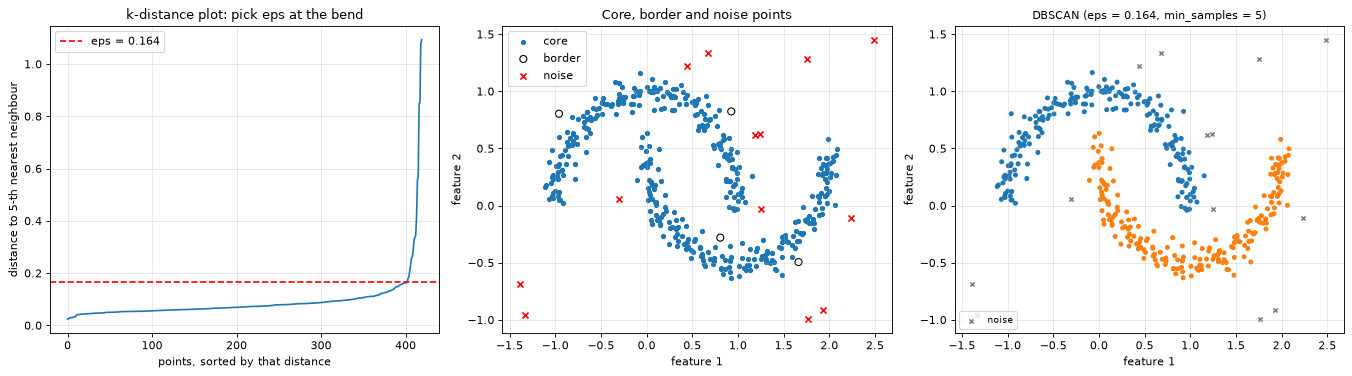

In [2]:
X7, y7 = make_moons(400, noise=0.07, random_state=SEED)
X7 = np.vstack([X7, np.random.default_rng(SEED).uniform([-1.5, -1], [2.5, 1.5], size=(20, 2))])   # 20 stray points
y7 = np.append(y7, [-1] * 20)
MIN_SAMPLES = 5                                                          # <- try 3 or 10

# k-distance plot: distance from each point to its MIN_SAMPLES-th nearest neighbour (counting itself), sorted
k_dist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X7).kneighbors(X7)[0][:, -1])
eps = float(k_dist[knee_by_chord(np.arange(len(k_dist)), k_dist)])      # where the sorted curve bends upward
db = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(X7)
core = np.zeros(len(X7), bool); core[db.core_sample_indices_] = True
border = (db.labels_ != -1) & ~core
print(f"eps chosen at the knee of the k-distance curve: {eps:.3f}")
print(f"core points {core.sum()}, border points {border.sum()}, noise points {(db.labels_ == -1).sum()}; "
      f"clusters found: {db.labels_.max() + 1}")
moons_only = y7 != -1
print(f"ARI on the 400 moon points: DBSCAN {adjusted_rand_score(y7[moons_only], db.labels_[moons_only]):.2f}, "
      f"k-means (k = 2) {adjusted_rand_score(y7[moons_only], KMeans(2, n_init=10, random_state=SEED).fit_predict(X7)[moons_only]):.2f}")
print(f"of the 20 stray points, DBSCAN called {(db.labels_[~moons_only] == -1).sum()} noise")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].plot(k_dist); axes[0].axhline(eps, color="red", ls="--", label=f"eps = {eps:.3f}")
axes[0].set_xlabel("points, sorted by that distance"); axes[0].set_ylabel(f"distance to {MIN_SAMPLES}-th nearest neighbour")
axes[0].set_title("k-distance plot: pick eps at the bend"); axes[0].legend()
for mask, style, label in [(core, dict(s=14), "core"), (border, dict(s=40, facecolors="none", edgecolors="k"), "border"),
                           (db.labels_ == -1, dict(s=30, marker="x", c="red"), "noise")]:
    axes[1].scatter(X7[mask, 0], X7[mask, 1], label=label, **style)
axes[1].set_xlabel("feature 1"); axes[1].set_ylabel("feature 2"); axes[1].set_title("Core, border and noise points")
axes[1].legend()
plot_clusters(axes[2], X7, db.labels_, f"DBSCAN (eps = {eps:.3f}, min_samples = {MIN_SAMPLES})")
axes[2].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: the sorted k-distances are flat (inside the moons) and then shoot up (the strays). The bend gives
>   **eps = 0.164**.
> * Middle: **403 core** points (the bulk), **4 border** points (circles at the edges) and **13 noise** points
>   (red ×).
> * Right: DBSCAN finds **2 clusters** and matches the two moons exactly (**ARI 1.00** on the moon points), where k-means
>   gets 0.26. Of the 20 stray points, 13 are called noise; the other 7 happened to land within `eps` of a moon and
>   joined it.
> * `min_samples` is the smoothing knob: larger values need denser regions to start a cluster and label more points as
>   noise. A common starting point is 2 × the number of features; here 5 for 2 features.

<a id="lab-8"></a>

## Lab 8 · DBSCAN's weak spot: one eps for every cluster

**Goal:** see how sensitive DBSCAN is to `eps` and `min_samples`, and what happens when clusters have different
densities (README §5.4). Left: the moons over a grid of settings. Right: two dense blobs close together and one sparse
blob far away, at three values of `eps`.

moons: ARI for each (min_samples, eps); clusters found in brackets
  min_samples  3: 0.02 (37)  0.61 (5)  1.00 (2)  1.00 (2)  0.00 (1)  0.00 (1)
  min_samples  5: 0.01 (21)  0.60 (5)  1.00 (2)  1.00 (2)  0.00 (1)  0.00 (1)
  min_samples 10: 0.00 (0)  0.07 (21)  0.98 (2)  1.00 (2)  0.00 (1)  0.00 (1)
  min_samples 20: 0.00 (0)  0.00 (0)  0.02 (4)  0.97 (2)  0.00 (1)  0.00 (1)

three blobs, two dense and close, one sparse and far:
  eps 0.25: 2 clusters; dense blobs merged: no ; sparse blob called noise: 100%
  eps 0.60: 3 clusters; dense blobs merged: yes; sparse blob called noise: 70%
  eps 1.20: 2 clusters; dense blobs merged: yes; sparse blob called noise: 10%


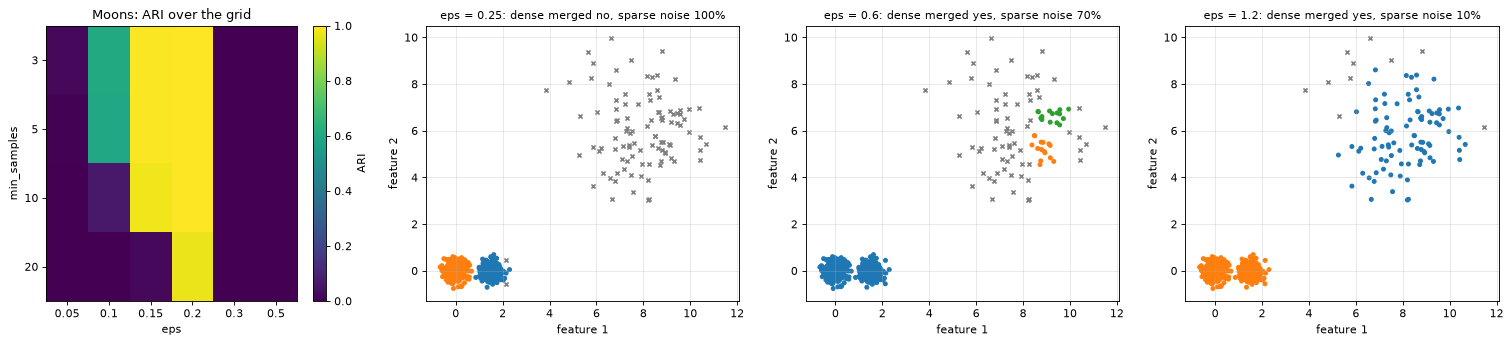

In [3]:
eps_grid = [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
ms_grid = [3, 5, 10, 20]
grid = np.array([[adjusted_rand_score(y7[moons_only], DBSCAN(eps=e, min_samples=m).fit_predict(X7)[moons_only])
                  for e in eps_grid] for m in ms_grid])
n_found = np.array([[DBSCAN(eps=e, min_samples=m).fit_predict(X7).max() + 1 for e in eps_grid] for m in ms_grid])

X_dens, y_dens = make_blobs([300, 300, 100], centers=[[0, 0], [1.5, 0], [8, 6]], cluster_std=[0.25, 0.25, 1.5],
                            random_state=SEED)                   # two dense blobs close together, one sparse blob far away


def density_report(labels):
    """What happened to the three true blobs: did the two dense ones (0, 1) end up in one cluster, and how much of
    the sparse one (2) was called noise?"""
    dense_a, dense_b = [np.bincount(labels[y_dens == g] + 1).argmax() - 1 for g in (0, 1)]   # majority label
    merged = dense_a == dense_b and dense_a != -1
    return labels.max() + 1, merged, np.mean(labels[y_dens == 2] == -1)


print("moons: ARI for each (min_samples, eps); clusters found in brackets")
for m, row, found in zip(ms_grid, grid, n_found):
    print(f"  min_samples {m:2d}: " + "  ".join(f"{a:4.2f} ({f})" for a, f in zip(row, found)))
print("\nthree blobs, two dense and close, one sparse and far:")
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
image = axes[0].imshow(grid, cmap="viridis", vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(eps_grid)), eps_grid); axes[0].set_yticks(range(len(ms_grid)), ms_grid)
axes[0].set_xlabel("eps"); axes[0].set_ylabel("min_samples"); axes[0].set_title("Moons: ARI over the grid")
axes[0].grid(False); fig.colorbar(image, ax=axes[0], label="ARI")
for ax, e in zip(axes[1:], [0.25, 0.6, 1.2]):
    labels = DBSCAN(eps=e, min_samples=10).fit_predict(X_dens)
    found, merged, sparse_noise = density_report(labels)
    print(f"  eps {e:4.2f}: {found} clusters; dense blobs merged: {'yes' if merged else 'no '}; "
          f"sparse blob called noise: {sparse_noise:.0%}")
    plot_clusters(ax, X_dens, labels, f"eps = {e}: dense merged {'yes' if merged else 'no'}, sparse noise {sparse_noise:.0%}")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Moons grid:** the right answer (ARI ≈ 1, 2 clusters) only appears for **eps 0.15–0.2**. Smaller eps shatters the
>   moons into many small clusters (37 at eps 0.05, min_samples 3) or calls everything noise (0 clusters); larger eps
>   merges both moons into one cluster.
> * **Mixed densities**, `min_samples` = 10:
>   * **eps 0.25** separates the two dense blobs but calls **100 %** of the sparse blob noise;
>   * **eps 0.6** has already merged the dense blobs and still calls **70 %** of the sparse blob noise (the rest
>     becomes two fragments);
>   * **eps 1.2** finally finds the sparse blob (**10 %** noise) but has merged the dense blobs.
> * No single `eps` gets all three. The dense blobs need a small radius and the sparse one a large radius: that is
>   exactly the problem OPTICS and HDBSCAN solve ([Lab 9](../04-optics-hdbscan/optics_hdbscan_lab.ipynb#lab-9)).

---

<a id="summary"></a>

# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| [7](#lab-7) | DBSCAN finds any shape and flags noise; eps from the k-distance bend | ✔ moons ARI 1.00 vs k-means 0.26 |
| [8](#lab-8) | One eps can't fit clusters of different density | ✘ eps 0.25 loses the sparse blob, eps 1.2 merges the dense ones |